<a href="https://colab.research.google.com/github/Guilherme-Prad/Simulador-de-decisoes/blob/main/%5BNome_1_e_Nome_2%5D_Projeto_A3_Matem%C3%A1tica_Computacional_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de Vendas de uma Loja (Superstore)
Dataset: *Superstore Dataset* (Kaggle)
- **Link Download usando kagglehub**: vivek468/superstore-dataset-final

Neste notebook você vai usar conhecimentos sobre: `rename`, `drop`, `apply`, `lambda`, novas colunas, `groupby`, `sort_values` e também **soma**, **média** e **porcentagem**.

1. Roberto marinho dos santos silva 1012522489
2. Luis Filipe da Silva Rocha 1012522594

## 1. Baixar e carregar os dados

Seção 1: Item 1 ao 4 = 6 pontos (1,5 ponto cada); Item 5 = 4 pontos

In [11]:
import os
import pandas as pd
import kagglehub as kh
import matplotlib.pyplot as plt

In [2]:
path = kh.dataset_download('vivek468/superstore-dataset-final')

Using Colab cache for faster access to the 'superstore-dataset-final' dataset.


In [12]:
arquivos = [arquivo for arquivo in os.listdir(path) if arquivo.endswith('.csv')]
pathJoin = os.path.join(path, arquivos[0])


In [17]:
df = pd.read_csv(pathJoin, encoding='windows-1252')

## 2. Conhecer as colunas

In [18]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

## 3. Remover colunas que não vamos usar (`drop`)

In [38]:
df = df[['Order Date', 'Segment', 'State', 'Region',
         'Category', 'Sub-Category', 'Sales',
         'Quantity', 'Discount', 'Profit']].copy()

df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200


Manter apenas estas colunas para começar:
- **Order Date:** data_pedido
- **Segment:** segmento
- **State:** Estado
- **Region:** região
- **Category:** categoria
- **Sub-Category:** subcategoria
- **Sales:** vendas
- **Quantity:** quantidade
- **Discount:** desconto
- **Profit:** lucro


In [ ]:
# Manter no dataset as colunas citadas acima e exlcuir as demais

## 4. Renomear colunas (`rename`)

In [30]:
df.rename(columns={
    'Order Date': 'data_pedido',
    'Segment': 'segmento',
    'State': 'estado',
    'Region': 'regiao',
    'Category': 'categoria',
    'Sub-Category': 'subcategoria',
    'Sales': 'vendas',
    'Quantity': 'quantidade',
    'Discount': 'desconto',
    'Profit': 'lucro'
}, inplace=True)

In [31]:
df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200


Visualizar dataset

In [ ]:
# Visualizar dataset com as colunas renomeadas

## 5. Criar novas colunas (`apply` e `lambda`)

In [32]:
df['ano'] = df['data_pedido'].astype(str).apply(
    lambda x: x.split('/')[-1]
)

In [33]:
df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro,ano
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,2016
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820,2016
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,2016
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310,2015
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,2015
...,...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028,2014
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332,2017
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932,2017
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200,2017


**Ano do pedido** (a data está no formato mês/dia/ano, então pegue a última parte da string):

In [34]:
df['situacao'] = df['lucro'].apply(
    lambda x: 'Lucro' if x > 0 else 'Prejuízo'
)

In [35]:
df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro,ano,situacao
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,2016,Lucro
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820,2016,Lucro
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,2016,Lucro
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310,2015,Prejuízo
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,2015,Lucro
...,...,...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028,2014,Lucro
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332,2017,Lucro
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932,2017,Lucro
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200,2017,Lucro


In [36]:
df['faixa_desconto'] = df['desconto'].apply(
    lambda x: 'Sem desconto' if x == 0.0
    else 'Até 20%' if x <= 0.20
    else 'Acima de 20%'
)

In [37]:
df

,data_pedido,segmento,estado,regiao,categoria,subcategoria,vendas,quantidade,desconto,lucro,ano,situacao,faixa_desconto
0,11/8/2016,Consumer,Kentucky,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,2016,Lucro,Sem desconto
1,11/8/2016,Consumer,Kentucky,South,Furniture,Chairs,731.9400,3,0.00,219.5820,2016,Lucro,Sem desconto
2,6/12/2016,Corporate,California,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,2016,Lucro,Sem desconto
3,10/11/2015,Consumer,Florida,South,Furniture,Tables,957.5775,5,0.45,-383.0310,2015,Prejuízo,Acima de 20%
4,10/11/2015,Consumer,Florida,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,2015,Lucro,Até 20%
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,Consumer,Florida,South,Furniture,Furnishings,25.2480,3,0.20,4.1028,2014,Lucro,Até 20%
9990,2/26/2017,Consumer,California,West,Furniture,Furnishings,91.9600,2,0.00,15.6332,2017,Lucro,Sem desconto
9991,2/26/2017,Consumer,California,West,Technology,Phones,258.5760,2,0.20,19.3932,2017,Lucro,Até 20%
9992,2/26/2017,Consumer,California,West,Office Supplies,Paper,29.6000,4,0.00,13.3200,2017,Lucro,Sem desconto


In [ ]:
# Acrescente a coluna ano ao final o dataset.

,data_pedido,ano
0,11/8/2016,2016
1,11/8/2016,2016
2,6/12/2016,2016
3,10/11/2015,2015
4,10/11/2015,2015


**Situação do pedido** (lucro ou prejuízo):
Crie uma nova coluna chamada situacao que mostrará 'Lucro' caso o lucro seja maior que 0, e 'Prejuízo' caso o lucro seja menor ou igual a 0.

In [ ]:
# Adicione ao final do dataset a coluna situação (Lucro ou Prejuízo)

,lucro,situacao
0,41.9136,Lucro
1,219.5820,Lucro
2,6.8714,Lucro
3,-383.0310,Prejuízo
4,2.5164,Lucro


**Faixa de desconto:**
Crie uma nova coluna chamada 'faixa_desconto' com os valores:

- **Sem desconto:** caso o desconto seja 0.0
- **Até 20%:** caso seja até 0.20
- **Acima de 20%:** caso seja maior que 0.2

In [ ]:
# Adicione ao final do dataset faixa_desconto

,desconto,faixa_desconto
0,0.00,Sem desconto
1,0.00,Sem desconto
2,0.00,Sem desconto
3,0.45,Acima de 20%
4,0.20,Até 20%


---
## Pergunta 1: Qual o total de vendas, de lucro e de itens vendidos? `(sum)`

Crie uma varíavel para cada e mostre seu valor formatado em 2 casas decimais.

Pergunta 1 = 2 pontos

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

Total de vendas: $ 2,297,200.86
Total de lucro: $ 286,397.02
Total de itens vendidos: 37873


## Pergunta 2: Quanto cada categoria vendeu e qual a porcentagem do total?

Pergunta 2 = 5 pontos

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

,categoria,vendas,percentual
2,Technology,836.2,36.4
0,Furniture,742.0,32.3
1,Office Supplies,719.0,31.3


Mostre o gráfico das categorias x vendas (qtd)
Converta as quantidades de vendas em mil. Ex.: `U$ 836.2 mil`, `U$ 742.0 mil`, `U$ 719.0 mil`

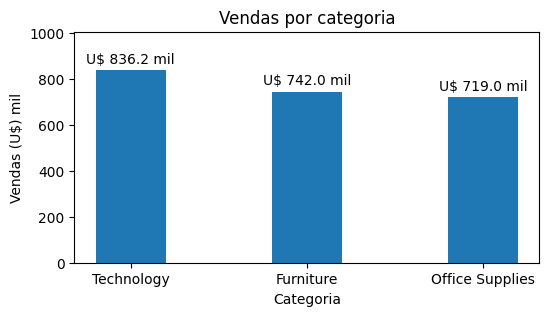

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

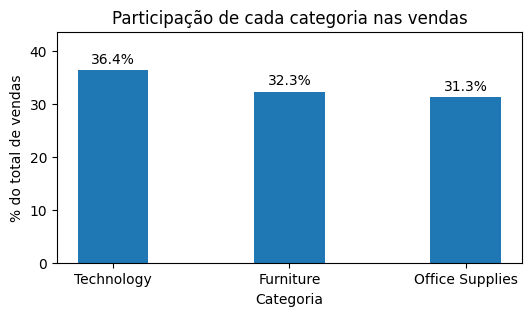

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 3: Qual região vende mais e qual tem a melhor margem de lucro?
**Margem de lucro** = lucro ÷ vendas × 100

Pergunta 3 = 4 pontos

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

,regiao,vendas,lucro,margem
3,West,725457.82,108418.45,14.94
1,East,678781.24,91522.78,13.48
0,Central,501239.89,39706.36,7.92
2,South,391721.91,46749.43,11.93


Mostre o gráfico da quantidade de vendas
- Formate os valores em mil. Ex.: `U$ 72.0 mil`, `U$ 15.0 mil`

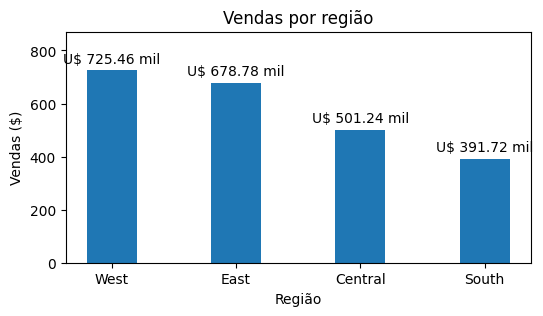

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

Mostre o gráfico do lucro
- Formate os valores em porcentagem com 1 casa decimal. Ex.: `10.5%`, `25.78%`

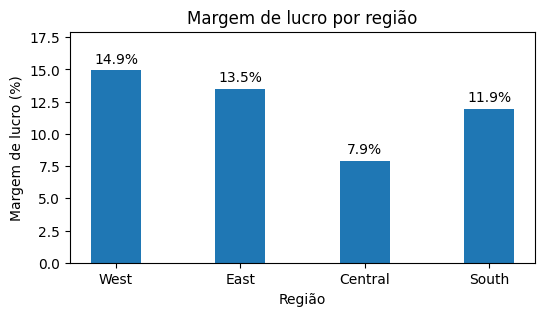

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 4: Como foram as vendas ao longo dos anos?
- Demonstre o quantitativo de vendas e o percentual de cada ano.
- Formate as vendas em mil e com 2 casas decimais. Ex.: `U$ 130.35 mil`
- Formate o percentual em 1 casa decimal. Ex.: `12.1%`

Pergunta 4 = 5 pontos

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

,ano,vendas,percentual
0,2014,484.25,21.1
1,2015,470.53,20.5
2,2016,609.21,26.5
3,2017,733.22,31.9


Mostre o gráfico de Vendas (U$) x Ano

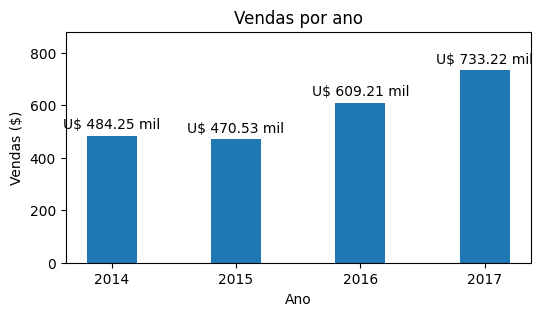

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 5: Qual a porcentagem de pedidos com lucro e com prejuízo?

Pergunta 5 = 3 pontos

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

,situacao,pedidos,percentual
0,Lucro,8058,80.6
1,Prejuízo,1936,19.4


Mostre o gráfico

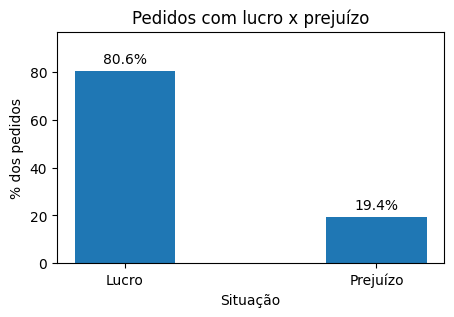

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 6: O desconto atrapalha o lucro? (`mean`)
- Use o lucro médio de cada faixa de desconto
- Use as faixas de desconto
1. Sem desconto: 0.00
2. Até 20%
3. Acima de 20%

Pergunta 6 = 4 pontos

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

,faixa_desconto,lucro_medio
2,Sem desconto,66.90
1,Até 20%,26.50
0,Acima de 20%,-97.18


Mostre o gráfico

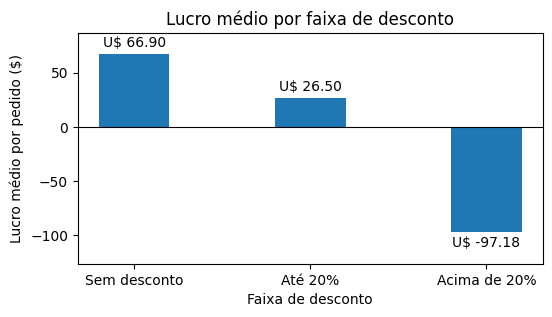

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 7: Quais subcategorias dão mais lucro? E quais dão prejuízo?

Pergunta 7 = 4 pontos

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

,subcategoria,lucro,quantidade
0,Accessories,41936.6357,2976
1,Appliances,18138.0054,1729
2,Art,6527.7870,3000
3,Binders,30221.7633,5974
4,Bookcases,-3472.5560,868
5,Chairs,26590.1663,2356
6,Copiers,55617.8249,234
7,Envelopes,6964.1767,906
8,Fasteners,949.5182,914
9,Furnishings,13059.1436,3563


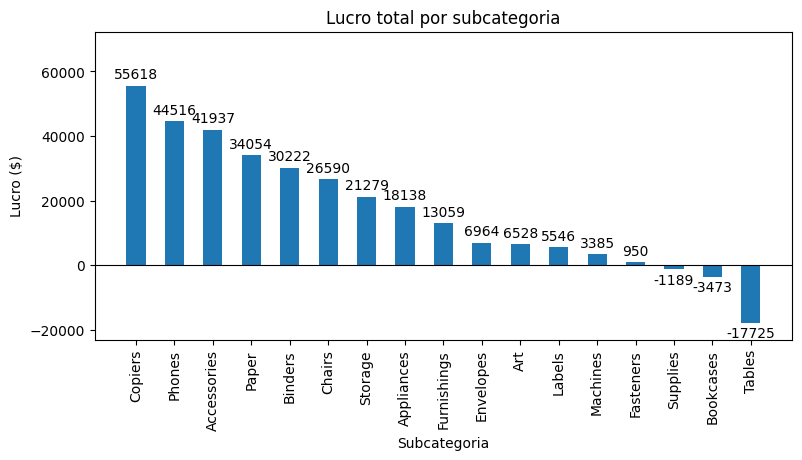

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

## Pergunta 8: Qual segmento de cliente tem o maior valor médio por venda?

Pergunta 8 = 3 pontos

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

,segmento,venda_media
2,Home Office,240.97
1,Corporate,233.82
0,Consumer,223.73


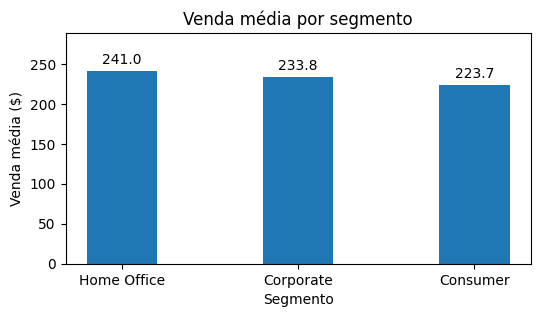

In [ ]:
# Código aqui para saída ser igual mostrado abaixo

---
## Resumo das fórmulas
| Cálculo | Como fazer |
|---|---|
| Soma | `.groupby('col')['valor'].sum()` |
| Média | `.groupby('col')['valor'].mean()` |
| Contagem | `.groupby('col').size()` |
| Porcentagem | `parte / total * 100` |
| Margem de lucro | `lucro / vendas * 100` |